# 02b · Clustering bike trips, simple version (Part A)

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Wrote and ran all code. This is a simplified version of notebook 02: 4 features, PCA, KMeans on the PCA scores, silhouette to choose K, a split-half stability check, profiles, link to station clusters.
- Chose the 4 features, the 90%-variance rule for keeping components, and 'highest silhouette' as the rule for K.

**Not done by Claude**
- No interpretation of any result and no written findings. Every `_Team notes:_` cell is left empty for the team.
- Cluster names or labels in words: none are given in the notebook.
- The team's own files (`data-cleanup.ipynb`, `Scratchpad.ipynb`, `FINDINGS.md`) were not edited.
- Time of day, weekend, e-bike and weather are not clustering features here. They are only used afterwards to describe the clusters.
- No GMM, Ward, Davies–Bouldin or Calinski–Harabasz comparison (they are in notebook 02).
- Notebook 03 still uses the labels from notebook 02, not these.

_Team notes:_

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import bikeshare_common as bc

bc.set_style()
pd.set_option("display.width", 200)
RNG = np.random.default_rng(0)

t = bc.load_clean("trips_clean")   # written by notebook 01
t.shape

(1161376, 42)

## 1. Four features per trip

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Log duration, log distance, straight-line speed, radial movement (clipped ±10 km).

In [2]:
X = pd.DataFrame({
    "log_duration": np.log(t.duration / 60),        # minutes, log because of the long tail
    "log_distance": np.log(t.distance),             # metres, straight line
    "speed_kmh": t.speed_kmh,
    # > 0: trip ends farther from the city centre than it started
    "radial_km": (t.dist_centre_end_km - t.dist_centre_start_km).clip(-10, 10),
})
X.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_duration,1161376.0,2.61,0.80,0.70,2.08,2.48,3.00,6.17
log_distance,1161376.0,7.24,0.71,3.91,6.79,7.21,7.71,9.90
speed_kmh,1161376.0,7.32,3.30,0.25,5.16,7.54,9.61,15.05
radial_km,1161376.0,0.19,1.64,-10.00,-0.67,0.12,0.91,10.00


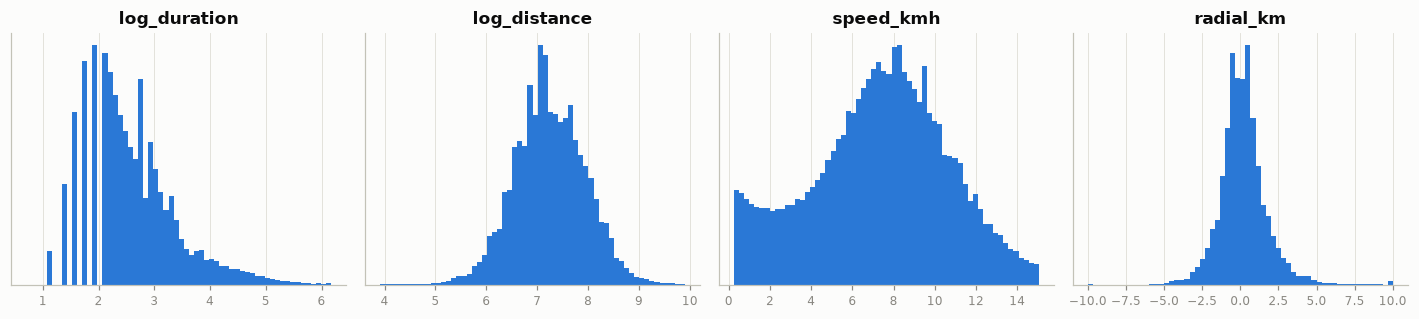

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(13, 3))
for a, col in zip(ax, X.columns):
    a.hist(X[col], bins=60, color=bc.SERIES[0])
    a.set(title=col, yticks=[])
plt.tight_layout()
plt.show()

_Team notes:_

## 2. Standardise

In [4]:
Z = StandardScaler().fit_transform(X)
pd.DataFrame(Z, columns=X.columns).describe().T[["mean", "std"]].round(2)

,mean,std
log_duration,-0.0,1.0
log_distance,-0.0,1.0
speed_kmh,0.0,1.0
radial_km,0.0,1.0


## 3. PCA

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- PCA on the standardised features. The smallest number of components reaching ≥ 90% of the variance is kept and used for clustering.

In [5]:
pca = PCA().fit(Z)
ev = pd.DataFrame({"eigenvalue": pca.explained_variance_, "explained": pca.explained_variance_ratio_,
                   "cumulative": pca.explained_variance_ratio_.cumsum()}, index=["PC1", "PC2", "PC3", "PC4"])
ev.round(3)

,eigenvalue,explained,cumulative
PC1,1.644,0.411,0.411
PC2,1.390,0.347,0.758
PC3,0.915,0.229,0.987
PC4,0.051,0.013,1.000


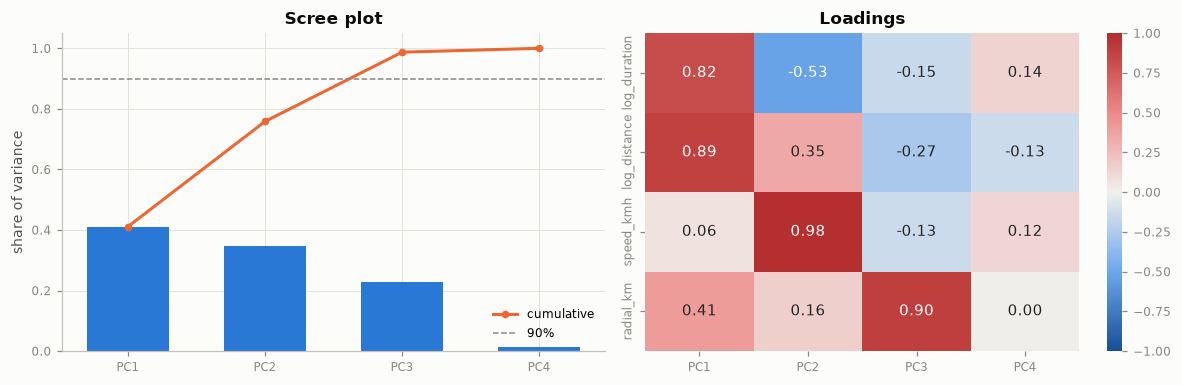

In [6]:
# loadings = correlation between each feature and each component
load = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_), index=X.columns, columns=ev.index)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(ev.index, ev.explained, color=bc.SERIES[0], width=.6)
ax[0].plot(ev.index, ev.cumulative, color=bc.SERIES[1], marker="o", ms=4, label="cumulative")
ax[0].axhline(.9, color=bc.GREY, ls="--", lw=1, label="90%")
ax[0].set(title="Scree plot", ylabel="share of variance")
ax[0].legend()
sns.heatmap(load, cmap=bc.DIV, vmin=-1, vmax=1, annot=True, fmt=".2f", ax=ax[1])
ax[1].set_title("Loadings")
plt.tight_layout()
plt.show()

In [7]:
# keep the smallest number of components that explains at least 90% of the variance
N_PC = int((ev.cumulative < 0.9).sum() + 1)
P = pca.transform(Z)[:, :N_PC]
print("components kept:", N_PC, "| variance kept:", ev.cumulative.iloc[N_PC - 1].round(3))

components kept: 3 | variance kept: 0.987


_Team notes:_

## 4. How many clusters?

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- KMeans for k = 2..8 on all trips; inertia, and silhouette on a 20k sample. K = k with the highest silhouette.

In [8]:
sample = RNG.choice(len(P), 20_000, replace=False)   # silhouette is slow, so it uses a sample
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=5, random_state=0).fit(P)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(P[sample], km.labels_[sample]),
                 "smallest_cluster": np.bincount(km.labels_).min() / len(P)})
sel = pd.DataFrame(rows).set_index("k")
sel.round(3)

,inertia,silhouette,smallest_cluster
k,,,
2,3410258.258,0.279,0.424
3,2550011.187,0.300,0.182
4,1972462.053,0.336,0.164
5,1670602.252,0.284,0.130
6,1481593.767,0.286,0.033
7,1325687.167,0.282,0.029
8,1215406.506,0.274,0.027


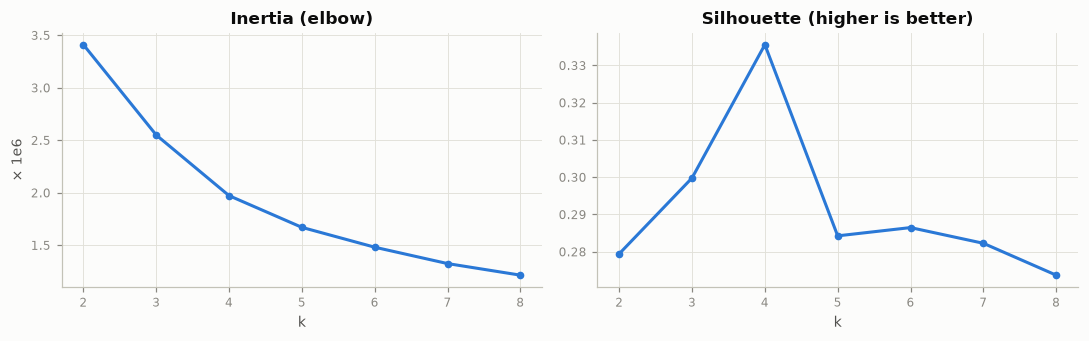

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(sel.index, sel.inertia / 1e6, marker="o", ms=4)
ax[0].set(title="Inertia (elbow)", xlabel="k", ylabel="× 1e6")
ax[1].plot(sel.index, sel.silhouette, marker="o", ms=4)
ax[1].set(title="Silhouette (higher is better)", xlabel="k")
plt.tight_layout()
plt.show()

In [10]:
K = int(sel.silhouette.idxmax())
print("chosen K (highest silhouette):", K)

chosen K (highest silhouette): 4


_Team notes:_

## 5. Final clustering and a stability check

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- KMeans with the chosen K, clusters renumbered by median duration; ARI between models fitted on two random halves.

In [11]:
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(P)
# renumber clusters by median duration so cluster 0 is the shortest
order = pd.Series(t.duration.values).groupby(km.labels_).median().sort_values().index
t["cluster"] = pd.Series(km.labels_).map({old: new for new, old in enumerate(order)}).values
t.cluster.value_counts(normalize=True).sort_index().round(3)

cluster
0    0.461
1    0.198
2    0.177
3    0.164
Name: proportion, dtype: float64

In [12]:
# fit on two random halves of the trips, label all trips with both models, compare
half = RNG.permutation(len(P))
a = KMeans(n_clusters=K, n_init=5, random_state=1).fit(P[half[: len(P) // 2]]).predict(P)
b = KMeans(n_clusters=K, n_init=5, random_state=2).fit(P[half[len(P) // 2:]]).predict(P)
print("ARI between the two halves:", round(adjusted_rand_score(a, b), 3))

ARI between the two halves: 0.995


_Team notes:_

## 6. What each cluster looks like

In [13]:
t["radial_km"] = X.radial_km.values
prof = t.groupby("cluster").agg(
    share=("cluster", lambda c: len(c) / len(t)),
    median_minutes=("duration", lambda d: d.median() / 60),
    median_km=("distance", lambda d: d.median() / 1000),
    median_speed_kmh=("speed_kmh", "median"),
    median_radial_km=("radial_km", "median"),
    start_km_from_centre=("dist_centre_start_km", "median"),
    end_km_from_centre=("dist_centre_end_km", "median"),
    p90_minutes=("duration", lambda d: d.quantile(.9) / 60),
)
prof.round(2)

,share,median_minutes,median_km,median_speed_kmh,median_radial_km,start_km_from_centre,end_km_from_centre,p90_minutes
cluster,,,,,,,,
0,0.46,8.0,0.94,7.21,0.10,0.95,1.06,12.0
1,0.20,14.0,2.18,9.56,-1.38,2.62,1.15,27.0
2,0.18,18.0,2.77,9.68,2.04,1.05,3.38,38.0
3,0.16,36.0,1.34,2.21,0.08,1.41,1.51,122.0


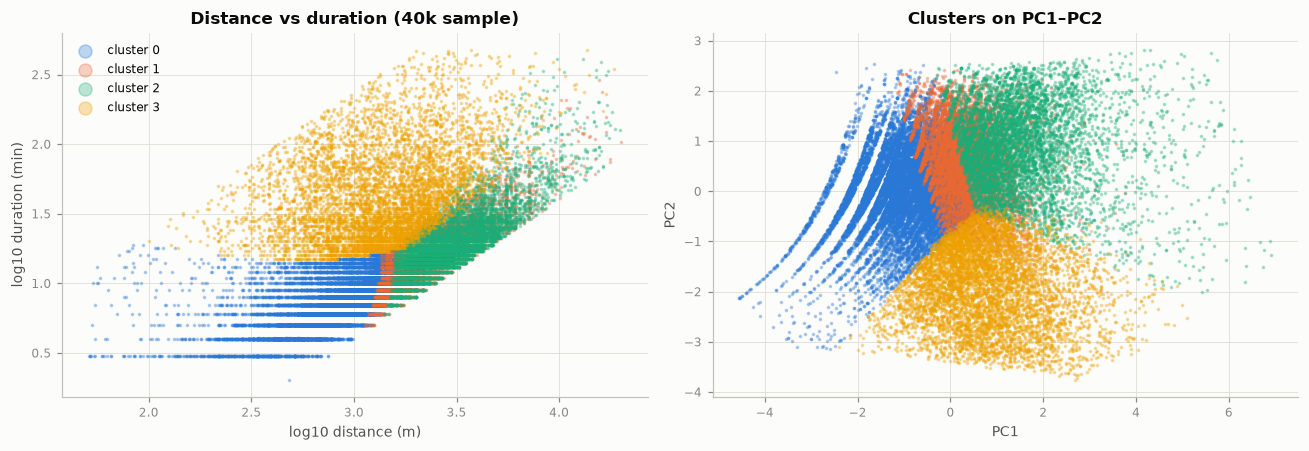

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
samp = t.sample(40_000, random_state=1)
scores = pca.transform(Z[samp.index])
for c in range(K):
    m = samp.cluster.values == c
    ax[0].scatter(np.log10(samp.distance[m]), np.log10(samp.duration[m] / 60), s=2, alpha=.3, color=bc.SERIES[c], label=f"cluster {c}")
    ax[1].scatter(scores[m, 0], scores[m, 1], s=2, alpha=.3, color=bc.SERIES[c])
ax[0].set(title="Distance vs duration (40k sample)", xlabel="log10 distance (m)", ylabel="log10 duration (min)")
ax[0].legend(markerscale=6)
ax[1].set(title="Clusters on PC1–PC2", xlabel="PC1", ylabel="PC2")
plt.tight_layout()
plt.show()

_Team notes:_

## 7. When do the clusters happen?

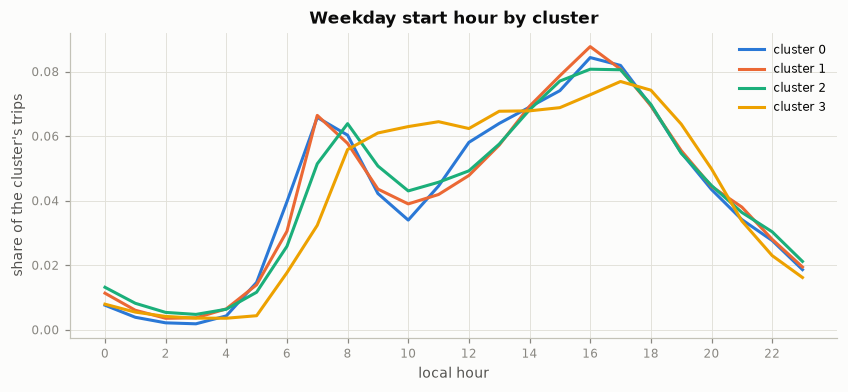

In [15]:
hp = t[t.weekend == 0].groupby(["cluster", "hour"]).size()
hp = hp / hp.groupby(level=0).transform("sum")
fig, ax = plt.subplots(figsize=(9, 3.6))
for c in range(K):
    ax.plot(range(24), hp.loc[c].reindex(range(24), fill_value=0), color=bc.SERIES[c], label=f"cluster {c}")
ax.set(title="Weekday start hour by cluster", xlabel="local hour", ylabel="share of the cluster's trips", xticks=range(0, 24, 2))
ax.legend()
plt.show()

In [16]:
t.groupby("cluster").agg(weekend=("weekend", "mean"), ebike=("ebike", "mean"),
                         rain_hour=("precipitation", lambda p: (p > 0.1).mean()),
                         temperature=("temperature_2m", "mean")).round(3)

,weekend,ebike,rain_hour,temperature
cluster,,,,
0,0.196,0.125,0.082,13.989
1,0.241,0.158,0.078,14.233
2,0.255,0.238,0.079,14.940
3,0.283,0.148,0.076,15.541


In [17]:
weather = np.where((t.temperature_2m >= 15) & (t.precipitation < 0.1), "warm & dry",
                   np.where((t.temperature_2m < 8) | (t.precipitation >= 0.5), "cold or wet", "mild"))
season = t.start_local.dt.month.map({12: "winter", 1: "winter", 2: "winter", 6: "summer", 7: "summer", 8: "summer"}).fillna("spring/autumn")
for name, var in [("weather", weather), ("season", season), ("weekend", t.weekend)]:
    print(pd.crosstab(var, t.cluster, normalize="index").round(3), "\n")

cluster          0      1      2      3
row_0                                  
cold or wet  0.513  0.197  0.163  0.127
mild         0.461  0.207  0.173  0.158
warm & dry   0.433  0.192  0.187  0.188 

cluster            0      1      2      3
start_local                              
spring/autumn  0.461  0.201  0.174  0.164
summer         0.439  0.195  0.184  0.182
winter         0.507  0.194  0.173  0.126 

cluster      0      1      2      3
weekend                            
0        0.481  0.196  0.171  0.153
1        0.394  0.208  0.196  0.202 



In [18]:
big = t.country.value_counts()
big = big[big > 20_000].index
pd.crosstab(t.country[t.country.isin(big)], t.cluster[t.country.isin(big)], normalize="index").round(2)

cluster,0,1,2,3
country,,,,
AT,0.49,0.22,0.15,0.14
CH,0.57,0.09,0.19,0.14
CZ,0.71,0.13,0.07,0.09
DE,0.53,0.18,0.16,0.13
ES,0.43,0.14,0.27,0.16
GB,0.19,0.34,0.33,0.14
HR,0.26,0.30,0.23,0.20
PL,0.41,0.22,0.14,0.24
SI,0.36,0.29,0.20,0.15


In [19]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    return np.sqrt(chi2_contingency(ct)[0] / (ct.values.sum() * (min(ct.shape) - 1)))


pd.Series({name: cramers_v(t.cluster, var) for name, var in
           [("country", t.country), ("ebike", t.ebike), ("weekend", t.weekend), ("weather", weather), ("month", t.month)]},
          name="Cramér's V").round(3).to_frame()

,Cramér's V
country,0.170
ebike,0.112
weekend,0.079
weather,0.056
month,0.045


_Team notes:_

## 8. Link with station clusters (Part B, notebook 03)

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Crosstab with the station clusters from notebook 03, Cramér's V and lift.

In [20]:
st = bc.load_clean("station_clusters").set_index("station_id").station_cluster
t["start_station_cluster"] = t.station_id_start.map(st)
linked = t[t.start_station_cluster >= 0]
ct = pd.crosstab(linked.start_station_cluster.astype(int), linked.cluster)
chi2 = chi2_contingency(ct)[0]
print("trips linked to a station cluster:", round(len(linked) / len(t), 3))
print("Cramér's V:", round(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))), 3))

trips linked to a station cluster: 0.851
Cramér's V: 0.123


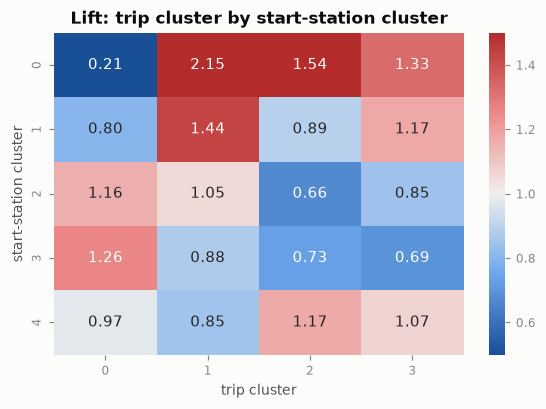

In [21]:
# lift = share of a trip cluster at this kind of station / its share overall (1 = no difference)
lift = ct.div(ct.sum(axis=1), axis=0) / (ct.sum(axis=0) / ct.values.sum())
fig, ax = plt.subplots(figsize=(6, 3.8))
sns.heatmap(lift, cmap=bc.DIV, center=1, vmin=.5, vmax=1.5, annot=True, fmt=".2f", ax=ax)
ax.set(title="Lift: trip cluster by start-station cluster", xlabel="trip cluster", ylabel="start-station cluster")
plt.show()

_Team notes:_

## 9. Save labels

In [22]:
bc.save_clean(t[["bike_id", "time_start", "city_id", "station_id_start", "station_id_end", "cluster"]], "trip_clusters_simple")